In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from amuse.units import units, constants, nbody_system
from amuse.datamodel import Particle, Particles
from amuse.ext.solarsystem import new_solar_system
from amuse.ext.orbital_elements import rel_posvel_arrays_from_orbital_elements
from amuse.community.huayno.interface import Huayno

In [ ]:
#functions!
def plot_disk(particles, time=None):
    moon = particles[0]
    debris = particles[1:]

    x = (debris.x - moon.x).value_in(units.km)
    y = (debris.y - moon.y).value_in(units.km)
    R = moon.radius.value_in(units.km)

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(x, y, s=8, label="Debris")
    ax.add_patch(plt.Circle((0, 0), R, color="gray"))

    ax.set_aspect("equal")
    ax.set_xlabel("x rel to Iapetus(km)")
    ax.set_ylabel("y rel to Iapetus(km)")
    ax.set_title(f"Debris disk at t = {time} days" if time is not None
                 else "Debris disk")
    ax.legend()
    plt.show()


def orbital_radii(particles):
    moon = particles[0]
    debris = particles[1:]

    r = (
        (debris.x - moon.x)**2 +
        (debris.y - moon.y)**2 +
        (debris.z - moon.z)**2
    ).sqrt()

    return r.value_in(units.km)


def compare_radii(initial, final):
    r0 = orbital_radii(initial)
    r1 = orbital_radii(final)
    dr = r1 - r0

    print(f"Initial mean radius: {r0.mean():.3f} km")
    print(f"Final mean radius:   {r1.mean():.3f} km")
    print(f"Change in mean:      {dr.mean():.3f} km")
    print(f"Mean absolute change:{np.abs(dr).mean():.3f} km")
    print(f"Maximum change:      {np.abs(dr).max():.3f} km")


def evolve_to(time_days, particles):
    gravity = Huayno(converter, channel_type="sockets")
    try:
        gravity.particles.add_particles(particles)
        gravity.evolve_model(time_days | units.day)
        result = gravity.particles.copy()
    finally:
        gravity.stop()

    return result

In [ ]:

#Set up
obj = new_solar_system()
new_system = obj[
    (obj.name == "SUN") |
    (obj.name == "JUPITER") |
    (obj.name == "SATURN")
].copy()
saturn = new_system[new_system.name == "SATURN"][0]

#iapetus properties from solar_system_moons.py
iapetus = Particle()
iapetus.name = "IAPETUS"
iapetus.mass = 1.81e21 | units.kg
iapetus.radius = 746 | units.km

#orbital parameters
a = 3560854 | units.km
e = 0.0293
M = np.deg2rad(201.789)  #mean anomaly

|S8


In [ ]:

#not exactly sure why i have to do this but it's in the textbook
E = M
for _ in range(6):
    E -= (E - e*np.sin(E) - M) / (1 - e*np.cos(E))

f = 2*np.arctan2(
    np.sqrt(1+e)*np.sin(E/2),
    np.sqrt(1-e)*np.cos(E/2)
)

In [ ]:

#calc orbital position and velocity
pos, vel = rel_posvel_arrays_from_orbital_elements(
    saturn.mass,
    iapetus.mass,
    a,
    eccentricity=e,
    true_anomaly=f | units.rad,
    inclination=8.298 | units.deg,
    argument_of_periapsis=271.606 | units.deg,
    longitude_of_the_ascending_node=81.105 | units.deg
)

#place iapetus around saturn
iapetus.position = saturn.position + pos[0]
iapetus.velocity = saturn.velocity + vel[0]
new_system.add_particle(iapetus)

N = 2000
debris = Particles(N)
np.random.seed(42)

#random positions in a disk around iapetus
r = np.random.uniform(1.3, 2.5, N) * iapetus.radius.value_in(units.km) | units.km
phi = np.random.uniform(0, 2*np.pi, N)
v = (constants.G * iapetus.mass / r).sqrt()

#particle properties
debris.mass = 0 | units.kg
debris.radius = 0 | units.km

#positions
debris.x = iapetus.x + r * np.cos(phi)
debris.y = iapetus.y + r * np.sin(phi)
debris.z = iapetus.z

#velocities
debris.vx = iapetus.vx - v * np.sin(phi)
debris.vy = iapetus.vy + v * np.cos(phi)
debris.vz = iapetus.vz

#finally making debris
new_system.add_particles(debris)

disk_system = Particles()
disk_system.add_particle(iapetus)
disk_system.add_particles(debris)
disk_system.move_to_center()

#making saturn
saturn_system = Particles()
saturn_system.add_particle(iapetus)
saturn_system.add_particles(debris)
saturn_system.add_particle(saturn)
saturn_system.move_to_center()

converter = nbody_system.nbody_to_si(iapetus.mass, iapetus.radius)

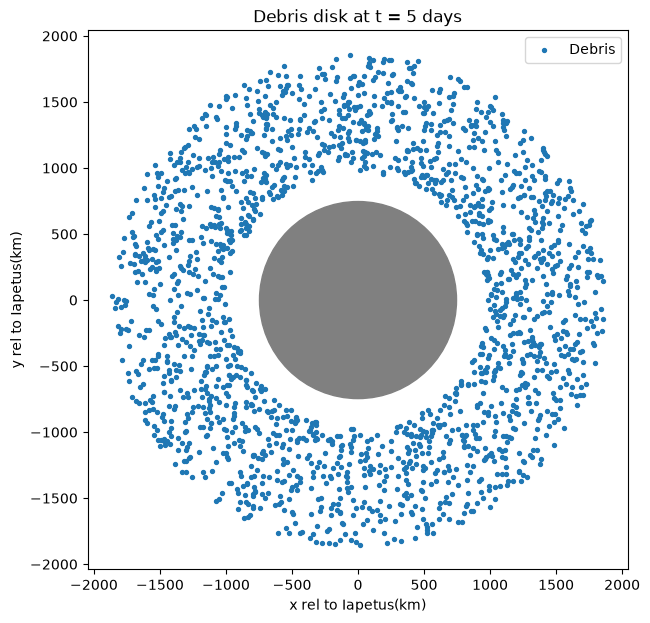

Without Saturn:
Initial mean radius: 1416.180 km
Final mean radius:   1416.227 km
Change in mean:      0.047 km
Mean absolute change:0.047 km
Maximum change:      0.157 km

With Saturn:
Initial mean radius: 1416.180 km
Final mean radius:   1416.230 km
Change in mean:      0.050 km
Mean absolute change:0.402 km
Maximum change:      5.436 km
Mean absolute difference: 0.392766031932 km
Maximum difference: 5.42726338936 km


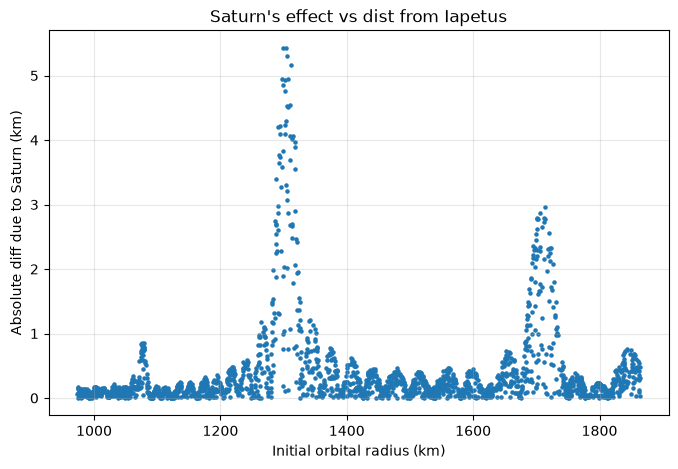

In [ ]:
after_no_saturn = evolve_to(5, disk_system)
after_saturn = evolve_to(5, saturn_system)

#plot debris disk with Saturn's gravity
plot_disk(after_saturn[:-1], time=5)

#compare orbital radii
print("Without Saturn:")
compare_radii(disk_system, after_no_saturn)

print("\nWith Saturn:")
compare_radii(saturn_system[:-1], after_saturn[:-1])

r_no = orbital_radii(after_no_saturn)
r_sat = orbital_radii(after_saturn[:-1])
difference = r_sat - r_no

print("Mean absolute difference:", np.abs(difference).mean(), "km")
print("Maximum difference:", np.abs(difference).max(), "km")

plt.figure(figsize=(8, 5))
plt.scatter(orbital_radii(disk_system), np.abs(difference), s=5)
plt.xlabel("Initial orbital radius (km)")
plt.ylabel("Absolute diff due to Saturn (km)")
plt.title("Saturn's effect vs dist from Iapetus")
plt.grid(alpha=0.3)
plt.show()


In [ ]:
/Users/ankitadasgupta/amuse-projects/IapetusandSaturn.ipynb